In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
plt.style.use('tableau-colorblind10')

## Pseudo-out-of-sample forecast evaluation

In [2]:
# Load data
df = pd.read_csv('data/CPIAUCSL.csv', index_col='observation_date', parse_dates=True)
df = df.interpolate() # interpolate missing value in Oct 2025
cpi = df['CPIAUCSL'].values
y = 100*np.diff(np.log(cpi)) # monthly inflation rate

print(f'Std dev of inflation: {y.std():.2f}')

Std dev of inflation: 0.34


In [3]:
from statsmodels.tsa.ar_model import AutoReg

# Date index for y (first CPI obs lost to differencing)
dates = df.index[1:]
T = len(y)

# First forecast origin: Dec 1969 (so first forecasted value is Jan 1970)
t_start = np.where(dates.year == 1969)[0][-1]  # last obs in 1969 = Dec 1969
n_fcs = T - 1 - t_start  # number of forecasts
fc_dates = dates[t_start + 1 : T]  # dates of forecasted values

# Storage
e_nc = np.zeros(n_fcs)   # no-change forecast errors
e_ar = np.zeros(n_fcs)   # AR forecast errors

p = 4  # AR lag order
for i, t in enumerate(range(t_start, T - 1)):
    # No-change forecast: y_{t+1|t} = y_t
    e_nc[i] = y[t + 1] - y[t]

    # AR(4) forecast: estimate on y_0, ..., y_t, predict y_{t+1}
    model = AutoReg(y[:t + 1], lags=p).fit()
    e_ar[i] = y[t + 1] - model.forecast(steps=1).item()

# RMSFE
rmsfe_nc = np.sqrt(np.mean(e_nc**2))
rmsfe_ar = np.sqrt(np.mean(e_ar**2))

print(f'Evaluation period: {fc_dates[0].strftime("%Y-%m")} to {fc_dates[-1].strftime("%Y-%m")} '
      f'({n_fcs} forecasts)')
print(f'{"":10s} {"RMSFE":>8s}')
print(f'{"No-change":10s} {rmsfe_nc:8.4f}')
print(f'{"AR(4)":10s} {rmsfe_ar:8.4f}')

Evaluation period: 1970-01 to 2026-02 (674 forecasts)
              RMSFE
No-change    0.2787
AR(4)        0.2500


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


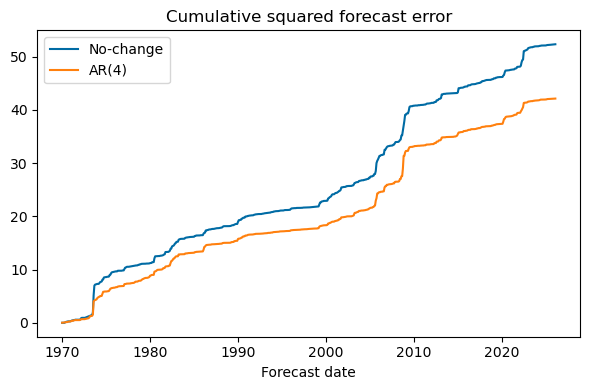

In [4]:
# Cumulative squared forecast errors
cum_sse_nc = np.cumsum(e_nc**2)
cum_sse_ar = np.cumsum(e_ar**2)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(fc_dates, cum_sse_nc, label='No-change')
ax.plot(fc_dates, cum_sse_ar, label='AR(4)')
ax.set_xlabel('Forecast date')
ax.set_title('Cumulative squared forecast error')
ax.legend()
fig.tight_layout()
fig.savefig('output/sfe.eps', format='eps')
plt.show()